In [15]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [19]:
number_of_realisations = 100
surface_temperature = 3300  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [92]:

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [17]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [23]:
ME = 5.972e24
RE = 6.371e6

# Lodders et al. (2009) Solar Abundances (wt%)
H_masspercent_lodders09 = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09 = 0.22
N_masspercent_lodders09 = 0.07
O_masspercent_lodders09 = 0.63

# Ratios relative to Hydrogen mass
C_H_RATIO = C_masspercent_lodders09 / H_masspercent_lodders09
N_H_RATIO = N_masspercent_lodders09 / H_masspercent_lodders09
He_H_RATIO = He_masspercent_lodders09 / H_masspercent_lodders09

def get_radius_from_mass(mass_kg):
    """Mass-Radius relationship: R ~ M^0.29"""
    m_earth_units = mass_kg / ME
    r_earth_units = 1.03 * (m_earth_units ** 0.29)
    return r_earth_units * RE

def get_solar_like_budget(h_kg):
    """Returns dictionary of element masses scaling with Hydrogen based on Lodders 09"""
    return {
        "H": h_kg,
        "C": h_kg * C_H_RATIO,
        "N": h_kg * N_H_RATIO,
        "He": h_kg * He_H_RATIO
    }

## Hydrogen fraction

Where does saturation occur

In [94]:
def vary_MASS():
    MASS = np.linspace(4, 20, number_of_realisations)
    MASSrange = []
    RADIUSrange = []
    for i in MASS:
        rratio = 1.03 * i**0.29
        rad = 6378137 * rratio
        mass =  5.97219e24 * i
        RADIUSrange.append(rad)
        MASSrange.append(mass)
        

    return MASSrange, RADIUSrange

In [95]:
log10_H_frac = np.full(number_of_realisations, 0)

log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar

get_solar_like_budget
h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}


In [96]:
sub_neptune = Planet(
        surface_temperature=surface_temperature,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction,
    )

In [97]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)
model = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

output_model = model.output

# Write the complete solution to Excel
file = output_model.to_excel("FILE8")

# Write the data to a pickle file with dataframes
output_model.to_pickle("FILE8")


[17:52:47 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[17:52:47 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:52:47 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[17:52:47 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[17:52:48 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[17:52:48 - atmodeller.classes             - INFO     ] - Solver steps (max) = 51
[17:52:48 - atmodeller.output              - INFO  

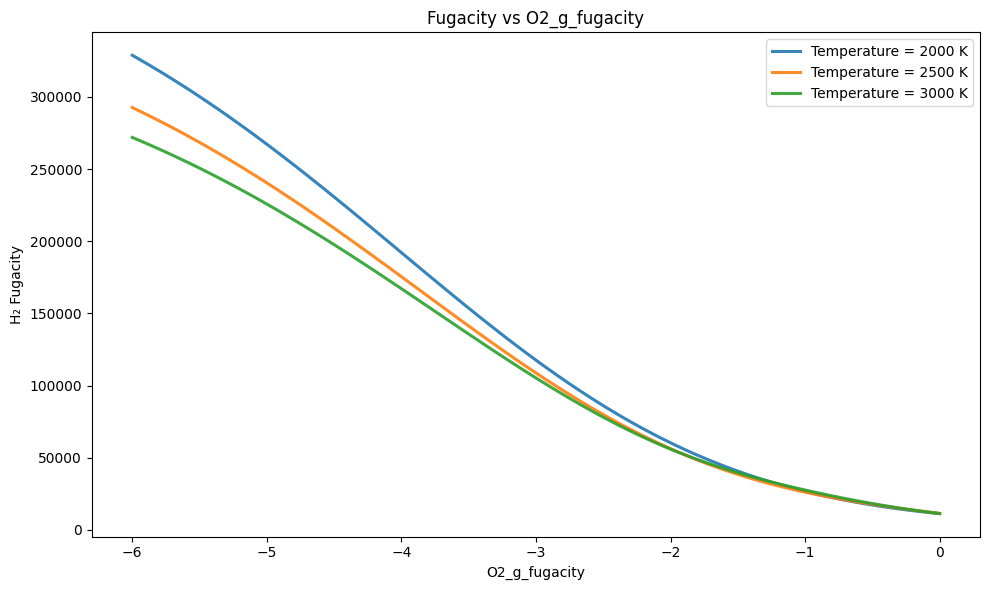

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

files = ['FILE5.xlsx', 'FILE6.xlsx', 'FILE7.xlsx']

fig, ax = plt.subplots(figsize=(10, 6))

for file in files:
    # Load sheets
    H2 = pd.read_excel(file, sheet_name='H2_g')
    O2 = pd.read_excel(file, sheet_name='O2_g')
    planet = pd.read_excel(file, sheet_name='planet')

    # Extract x/y
    x = O2['log10dIW_P']
    y = H2['fugacity']

    # If only 1 temperature exists, use it as label
    # Otherwise the label will display all of them (modify if needed)
    temp_val = planet['surface_temperature'][0]

    # Plot line for this temperature
    ax.plot(
        x,
        y,
        lw=2.2,
        alpha=0.9,
        label=f"Temperature = {temp_val} K"
    )

# --- Labels ---
ax.set_xlabel("O2_g_fugacity")
ax.set_ylabel("H₂ Fugacity")
ax.set_title("Fugacity vs O2_g_fugacity")
ax.legend()

plt.tight_layout()
plt.savefig("TandFO2.png", dpi=300)
plt.show()


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib import rcParams

def set_presentation_style():
    plt.rcdefaults()
    rcParams["font.family"] = "sans-serif"
    rcParams["font.size"] = 15
    rcParams["axes.labelsize"] = 18
    rcParams["axes.titlesize"] = 20
    rcParams["legend.fontsize"] = 15

palette_T = get_cmap("Set2")(np.linspace(0,1,3))
palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3))


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_9680/989106745.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_T = get_cmap("Set2")(np.linspace(0,1,3))
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_9680/989106745.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3))


In [7]:
def get_ratio_from_file(file):
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    return df_H2O["atmosphere_moles"] / df_H2["atmosphere_moles"]


In [10]:
def get_H_fraction(file):
    df_planet = pd.read_excel(file, sheet_name="planet")
    df_H = pd.read_excel(file, sheet_name="element_H")
    mass = df_planet["planet_mass"][0]
    return df_H["total_mass"] / mass   # dimensionless fraction


In [30]:
species = species_real
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

log10_H_frac = np.full(number_of_realisations, 0)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
mass_constraints = get_solar_like_budget(h_kg)
fO2_values = [-2, 0, 2]   # example offsets from IW buffer

for shift in fO2_values:

    print(f"Running model for fO₂ = IW{shift:+}")
    
    shifts = np.full(number_of_realisations, shift)
    
    sub_neptune = Planet(
        surface_temperature=2000,  # HOLD T CONSTANT
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction
    )

    fugacity_constraints = {O2_rg.name: IronWustiteBuffer(shifts) }

    model = InteriorAtmosphere(species)
    model.solve(
        planet=sub_neptune,
        mass_constraints=mass_constraints,
        fugacity_constraints=fugacity_constraints,
        solver_parameters=solver_parameters
    )

    output = model.output
    outfile = f"SUBNEPTUNE_REAL_fO2_{shift:+}"
    output.to_excel(outfile)
    print(f"✓ Saved {outfile}")


[13:50:50 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:50:50 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:50:50 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:50:50 - atmodeller.classes             - IN

Running model for fO₂ = IW-2


[13:50:55 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[13:50:55 - atmodeller.classes             - INFO     ] - Solver steps (max) = 66
[13:50:55 - atmodeller.output              - INFO     ] - Writing output to excel
[13:50:55 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:50:55 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:50:55 - atmodeller.output              - INFO     ] - Output written to SUBNEPTUNE_REAL_fO2_-2.xlsx
[13:50:55 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong

✓ Saved SUBNEPTUNE_REAL_fO2_-2
Running model for fO₂ = IW+0


[13:51:01 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[13:51:01 - atmodeller.classes             - INFO     ] - Solver steps (max) = 79
[13:51:01 - atmodeller.output              - INFO     ] - Writing output to excel
[13:51:01 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:51:01 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:51:02 - atmodeller.output              - INFO     ] - Output written to SUBNEPTUNE_REAL_fO2_+0.xlsx
[13:51:02 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong

✓ Saved SUBNEPTUNE_REAL_fO2_+0
Running model for fO₂ = IW+2


[13:51:07 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[13:51:07 - atmodeller.classes             - INFO     ] - Solver steps (max) = 67
[13:51:07 - atmodeller.output              - INFO     ] - Writing output to excel
[13:51:07 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:51:07 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:51:08 - atmodeller.output              - INFO     ] - Output written to SUBNEPTUNE_REAL_fO2_+2.xlsx


✓ Saved SUBNEPTUNE_REAL_fO2_+2


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_9680/4153775541.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_fO2 = get_cmap("tab20c")(np.linspace(0.1, 0.7, 3))


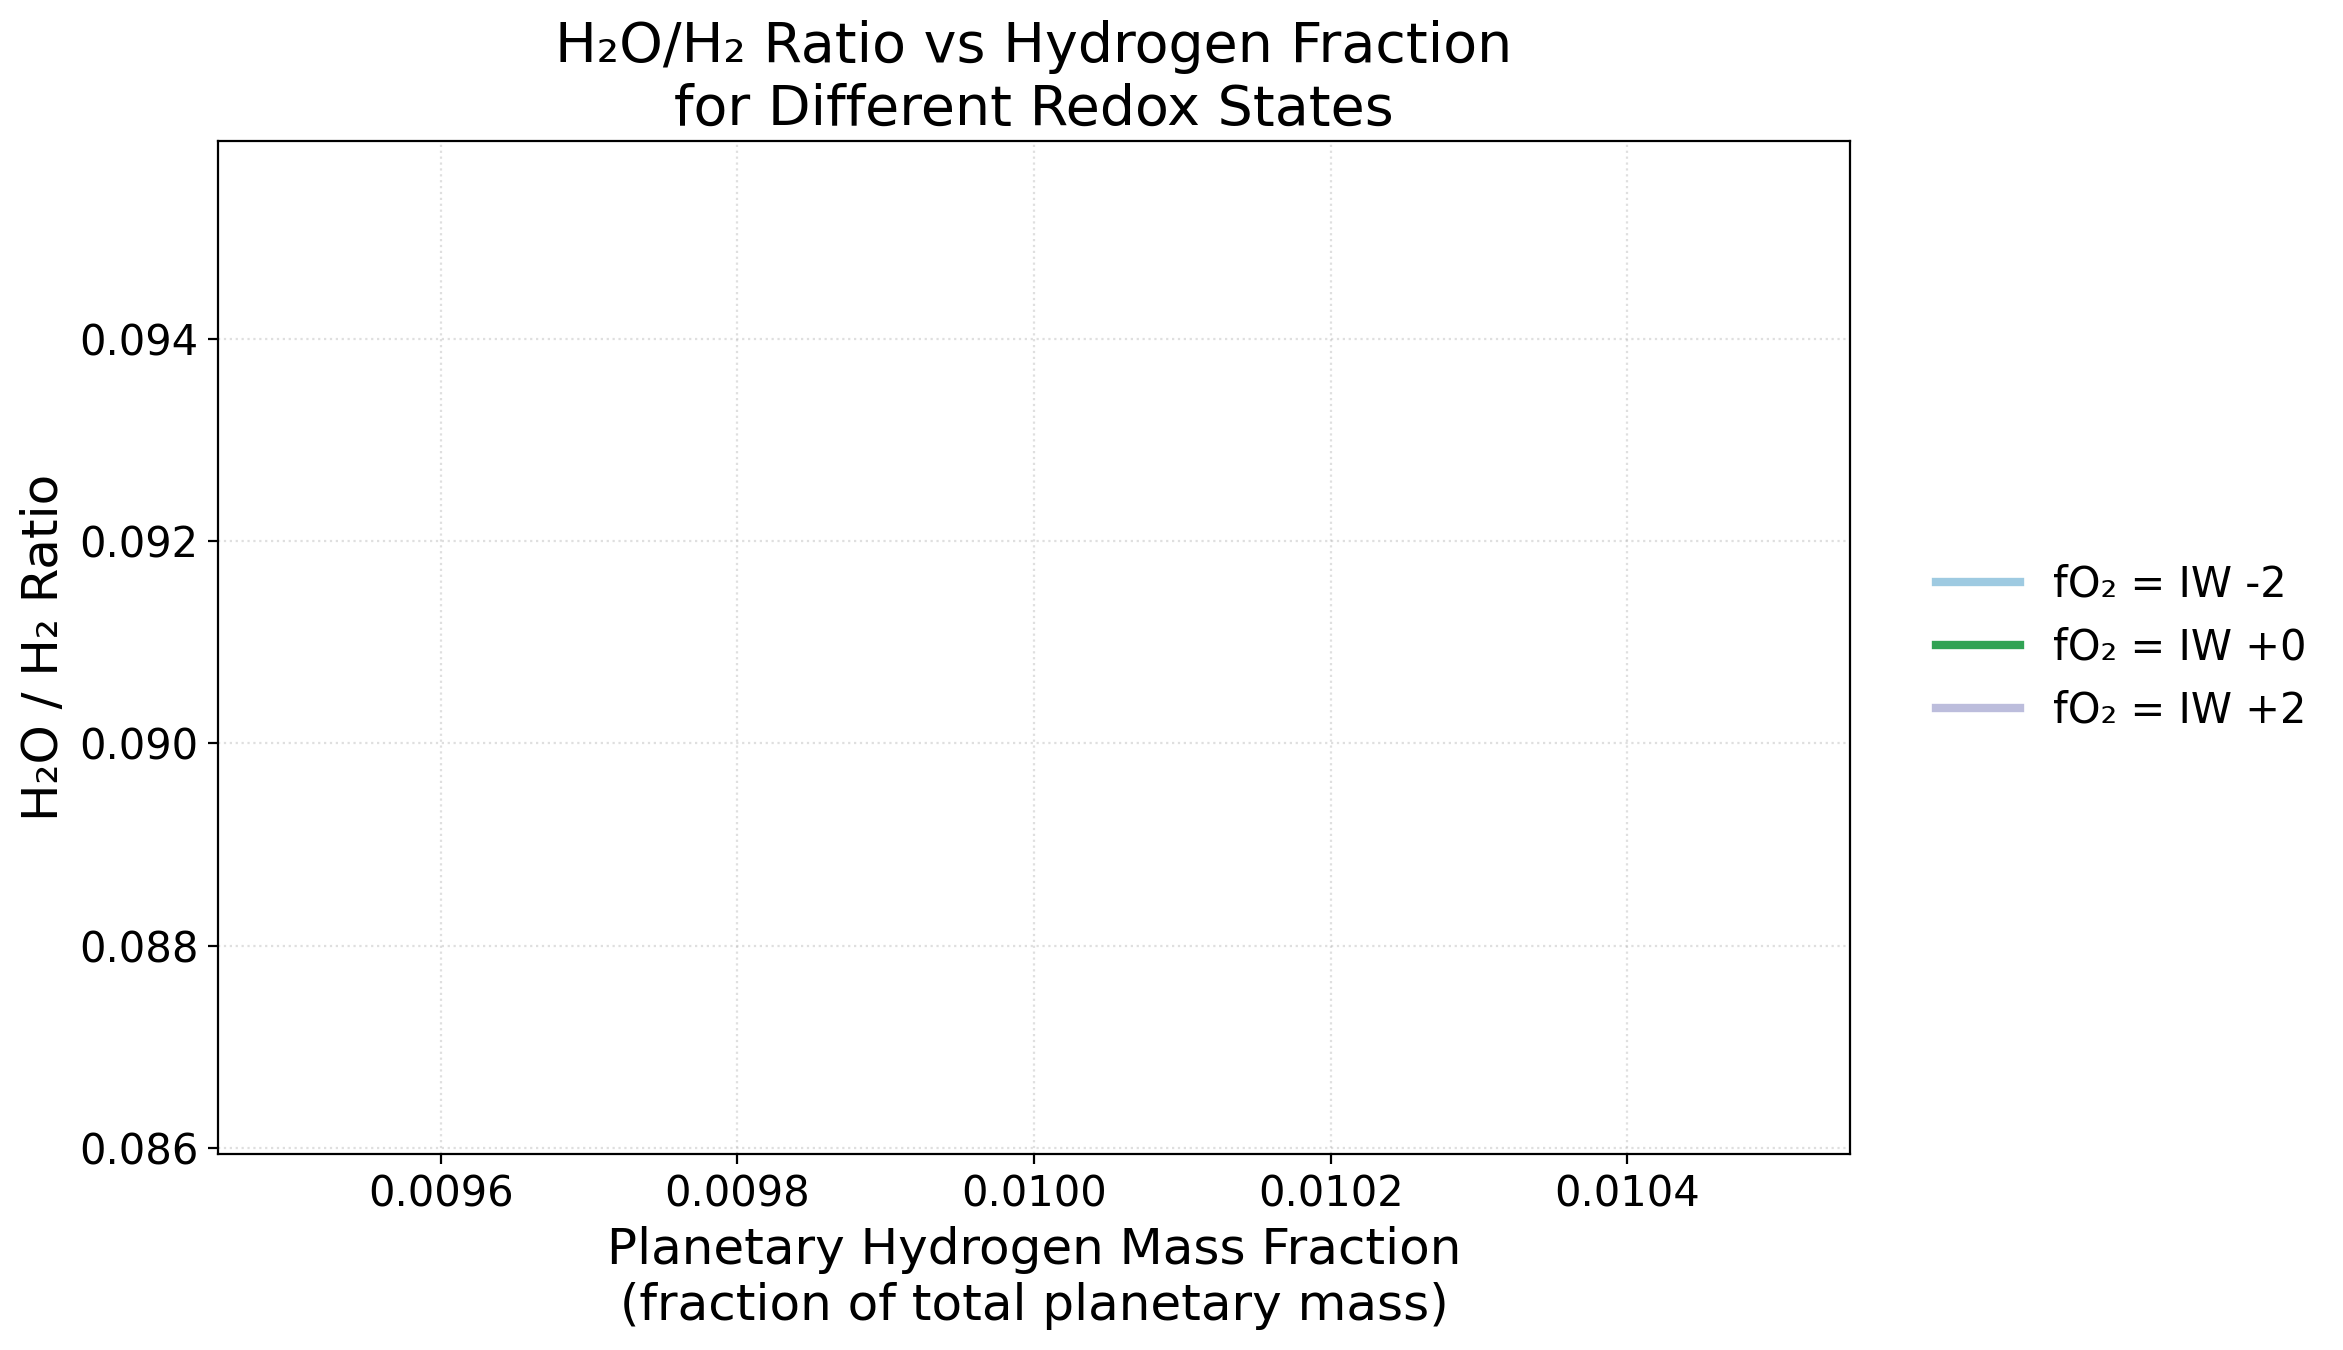

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib import rcParams

palette_fO2 = get_cmap("tab20c")(np.linspace(0.1, 0.7, 3))

def plot_ratio_vs_Hfrac_fO2(files, fO2_list, outfile):
    set_presentation_style()
    file = files[0]
    df_planet = pd.read_excel(file, sheet_name="planet")
    df_H = pd.read_excel(file, sheet_name="element_H")
    mass = df_planet["planet_mass"][0]
    H_frac = df_H["total_mass"] / mass
    ratios = []
    for f in files: 
        df_H2O = pd.read_excel(file, sheet_name="H2O_g")
        df_H2  = pd.read_excel(file, sheet_name="H2_g")
        ratio =  df_H2O["atmosphere_moles"] / df_H2["atmosphere_moles"]
        ratios.append(ratio)

    fig, ax = plt.subplots(figsize=(12, 7), dpi=200)

    for i, fO2 in enumerate(fO2_list):
        ax.plot(H_frac, ratios[i],
                label=f"fO₂ = IW {fO2:+}",
                lw=3,
                color=palette_fO2[i])

    ax.set_xlabel("Planetary Hydrogen Mass Fraction\n(fraction of total planetary mass)")
    ax.set_ylabel("H₂O / H₂ Ratio")
    ax.set_title("H₂O/H₂ Ratio vs Hydrogen Fraction\nfor Different Redox States")
    ax.grid(True, linestyle=":", alpha=0.4)

    ax.legend(loc="center left", bbox_to_anchor=(1.03, 0.5), frameon=False)
    fig.tight_layout()
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    return


files = [
    "SUBNEPTUNE_REAL_fO2_-2.xlsx",
    "SUBNEPTUNE_REAL_fO2_+0.xlsx",
    "SUBNEPTUNE_REAL_fO2_+2.xlsx"
]

plot_ratio_vs_Hfrac_fO2(files, [-2, 0, +2], "ratio_vs_Hfrac_fO2.png")
